# 01 · Job Market Analysis- Data Collection, Cleaning, EDA and Statistical Analysis

# 1. Configuration

In [1]:
# !pip install -r ../requirements.txt     # <- uncomment to install dependencies from inside Jupyter

import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)   # seaborn/matplotlib notices

# ---- paths -----------------------------------------------------------------------------------
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # project root
DATA_DIR = ROOT / "data"                       # configurable data directory
OUTPUT_DIR = ROOT / "outputs"                  # everything we save goes here
APP_DIR = ROOT / "app"                         # shared helper modules
DATA_FILE = DATA_DIR / "all_upwork_jobs_2024-02-07-2024-03-24.xlsx"
CLEAN_FILE = OUTPUT_DIR / "cleaned_jobs.csv.gz"
FIG_DIR = OUTPUT_DIR / "figures"
for d in (OUTPUT_DIR, FIG_DIR, DATA_DIR / "interim"):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(APP_DIR))
import job_taxonomy as jt        # title cleaning + rule-based categories (see app/job_taxonomy.py)
import preprocessing as pp       # reusable cleaning functions       (see app/preprocessing.py)

# ---- key settings ----------------------------------------------------------------------------
SEED = 42                      # reproducibility
MIN_N_COUNTRY = 30             # minimum hourly postings for a country to be reported (Task 4)
MIN_N_KEYWORD = 300            # minimum postings with pay for a keyword to be tested (Task 1)
ALPHA = 0.05                   # significance level (after multiple-testing correction)
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 10})
pd.options.display.float_format = "{:,.2f}".format
print("Project root:", ROOT)

Project root: d:\PERSONAL\Project 8


# 2. Data source


# 2. Loading the data

In [2]:
raw = pp.load_raw(DATA_FILE, cache_dir=DATA_DIR / "interim")
pp.validate_schema(raw)            # raises a helpful error for missing columns / empty files
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns from {DATA_FILE.name}")
raw.head()

Loaded 244,828 rows x 8 columns from all_upwork_jobs_2024-02-07-2024-03-24.xlsx


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.00,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,"1,100.00",United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.00,30.00,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.00,India


# 3. Inspecting the raw data


In [3]:
print("shape:", raw.shape)
raw.info()

shape: (244828, 8)
<class 'pandas.DataFrame'>
RangeIndex: 244828 entries, 0 to 244827
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   title           244818 non-null  str    
 1   link            244827 non-null  str    
 2   published_date  244828 non-null  str    
 3   is_hourly       244828 non-null  bool   
 4   hourly_low      102422 non-null  float64
 5   hourly_high     98775 non-null   float64
 6   budget          103891 non-null  float64
 7   country         239751 non-null  str    
dtypes: bool(1), float64(3), str(4)
memory usage: 13.3 MB


In [4]:
display(raw.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,244818,205461,Social Media Manager,419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
link,244827,244827,https://www.upwork.com/jobs/Experienced-Media-...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published_date,244828,233640,2024-02-24 13:04:28+00:00,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_hourly,244828,2,True,140937,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hourly_low,"102,422.00",NaN,NaN,NaN,17.34,18.14,3.00,8.00,15.00,20.00,998.00
hourly_high,"98,775.00",NaN,NaN,NaN,41.97,47.85,3.00,20.00,30.00,50.00,999.00
budget,"103,891.00",NaN,NaN,NaN,911.47,"15,729.74",5.00,25.00,100.00,300.00,"1,000,000.00"
country,239751,212,United States,99834,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# unique values, missing counts and percentages per column
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "n_missing": raw.isna().sum(),
    "pct_missing": raw.isna().mean() * 100,
})
display(profile)
print("Fully duplicated rows:", raw.duplicated().sum(),
      "| duplicated links:", raw["link"].duplicated().sum(),
      "| duplicated (title, timestamp):", raw.duplicated(["title", "published_date"]).sum())

,dtype,n_unique,n_missing,pct_missing
title,str,205461,10,0.00
link,str,244827,1,0.00
published_date,str,233640,0,0.00
is_hourly,bool,2,0,0.00
hourly_low,float64,114,142406,58.17
hourly_high,float64,227,146053,59.66
budget,float64,768,140937,57.57
country,str,212,5077,2.07


Fully duplicated rows: 0 | duplicated links: 0 | duplicated (title, timestamp): 14


**Reading the profile**
* `hourly_low`, `hourly_high`, `budget` are *structurally* missing: `budget` exists only for fixed-price jobs and the
  hourly bounds only for hourly jobs. Their missingness is not an error — we check this explicitly below.
* About 27–30 % of **hourly** postings state no rate (or only a lower bound). Those postings are kept for volume
  analyses and excluded only from pay analyses.
* `country` is missing for ~2 % of postings; we keep them (as missing, not as "Unknown") and drop them only from country analyses.

In [6]:
# Is the missingness structural? (hourly jobs should never carry a fixed budget and vice-versa)
chk = raw.groupby("is_hourly").agg(
    n=("title", "size"),
    has_budget=("budget", lambda s: s.notna().mean()),
    has_hourly_low=("hourly_low", lambda s: s.notna().mean()),
    has_hourly_high=("hourly_high", lambda s: s.notna().mean()))
display(chk)

,n,has_budget,has_hourly_low,has_hourly_high
is_hourly,,,,
False,103891,1.00,0.00,0.00
True,140937,0.00,0.73,0.70


## 4. Cleaning and preprocessing

In [7]:
df = pp.parse_dates(raw)
print("Unparseable dates:", int(df["published_at"].isna().sum()))
print("Date range:", df["published_at"].min(), "->", df["published_at"].max())
df = pp.add_job_id(df)
df = pp.add_time_columns(df)
coverage = pp.day_coverage(df)
core_start, core_end = pp.longest_complete_window(coverage)
print(f"Longest run of complete days (the 'core window'): {core_start.date()} -> {core_end.date()} "
      f"({(core_end - core_start).days + 1} days)")
display(coverage[~coverage["is_complete"]].tail(12))

Unparseable dates: 0
Date range: 2023-11-02 09:22:02+00:00 -> 2024-03-24 14:16:47+00:00
Longest run of complete days (the 'core window'): 2024-02-19 -> 2024-03-23 (34 days)


,date,n_postings,hours_covered,is_complete
42,2024-02-07,17,0,False
43,2024-02-08,21,0,False
44,2024-02-09,16,0,False
45,2024-02-10,8,0,False
46,2024-02-11,9,0,False
47,2024-02-12,31,0,False
48,2024-02-13,5062,16,False
49,2024-02-14,5966,21,False
50,2024-02-15,1811,6,False
52,2024-02-17,4717,23,False


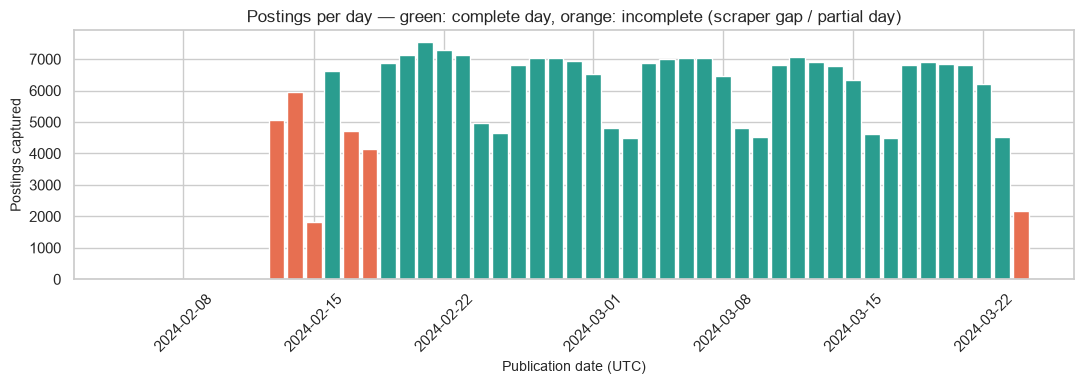

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))
recent = coverage[coverage["date"] >= "2024-02-05"]
colors = np.where(recent["is_complete"], "#2a9d8f", "#e76f51")
ax.bar(recent["date"], recent["n_postings"], color=colors, width=0.85)
ax.set_title("Postings per day — green: complete day, orange: incomplete (scraper gap / partial day)")
ax.set_xlabel("Publication date (UTC)"); ax.set_ylabel("Postings captured")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

**Findings and decisions**
* ~280 rows (0.1 %) are dated *before* 13 Feb 2024 (1–30 per day). They are almost certainly old postings that were still
  visible when the scraper started, not a real posting rate. We **keep** them in the cleaned file but they never count as "complete days".
* 13 Feb is partial (data starts ~08:00 UTC), **14 → 15 Feb contains a ~21-hour collection gap**, 17–18 Feb contain short
  outages (zero postings in a few hours), and 24 Mar ends at 14:16 UTC.
* Therefore the **core window** for trends, growth rates and forecasts is the longest run of fully covered days
  (printed above). Volume statistics from incomplete days would be biased downwards, so they are excluded from trend work —
  *not deleted from the data*.

### 4.1 Duplicates

In [9]:
df, dedupe_log = pp.drop_duplicates(df)
print(dedupe_log)
df, n_no_title = pp.drop_missing_titles(df)
print("Postings without a title removed:", n_no_title)

{'rows_in': 244828, 'dropped_same_link_or_id': 517, 'dropped_same_title_time_pay_country': 10, 'rows_out': 244301}
Postings without a title removed: 10


**Justification.** No link appears twice, but **517 rows share a job id with another row** (the same Upwork job scraped
twice, e.g. after the title was edited) and 10 more match on title + exact timestamp + pay + country. We drop
those 527 rows (0.2 %). Separately, **10 postings have no title** at all; without text they cannot be categorised, searched or
recommended, so they are removed (documented in the log above). We do **not** drop reposts of the same title at different times: each repost is a real new
posting and there is no client id to tell "the same employer re-listing" from "different employers with the same title".

### 4.2 Countries

In [10]:
df["country"] = pp.standardize_country(df["country"])
df["country_iso3"] = df["country"].map(pp.COUNTRY_ISO3)
unmapped = df.loc[df["country"].notna() & df["country_iso3"].isna(), "country"].unique()
print("Countries:", df["country"].nunique(), "| without ISO code:", list(unmapped))
print("Missing country (kept as missing):", df["country"].isna().sum())

Countries: 212 | without ISO code: []
Missing country (kept as missing): 5072


HTML entities (e.g. `Cote d&#039;Ivoire`) were decoded and a few legacy names modernised (`Macedonia → North Macedonia`,
`Czech Republic → Czechia`, …). All 212 distinct countries map to an ISO-3 code for the map in Task 4.

### 4.3 Pay: standardising amounts, pay types and currency
* **Currency.** The file has no currency column. Upwork displays rates and budgets in **US dollars**, so we *assume USD*
  and perform no exchange-rate conversion. This is an assumption (not verifiable from the data) and is repeated wherever it matters.
* **Hourly vs fixed price** are different quantities — never averaged together.
* **Hourly rate** = midpoint of `[hourly_low, hourly_high]` when both exist. If only the lower bound exists we keep it separately
  for a sensitivity check but do **not** treat it as the rate.
* **Fixed-price budgets are NOT converted to hourly rates:** that would require an hours estimate that the data does not contain.

In [11]:
df = pp.standardize_salary(df)
print(df["hourly_basis"].value_counts().to_string())
display(df.groupby("pay_type")["pay_value_usd"].describe(percentiles=[.05, .25, .5, .75, .95, .99]))

hourly_basis
n/a (fixed price)    103696
range                 98541
not disclosed         38415
lower bound only       3639


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
pay_type,,,,,,,,,,,
Fixed price,"103,696.00",910.56,"15,738.13",5.00,5.00,25.00,100.00,300.00,"2,000.00","9,999.00","1,000,000.00"
Hourly,"98,541.00",29.71,30.49,3.00,6.00,14.00,22.50,35.00,75.00,135.00,998.50


### 4.4 Outliers -genuine or erroneous?
Pay is strongly right-skewed, so "unusual" is judged on the **log scale** with the IQR rule, separately for each pay type.
Flagged values are **investigated, not automatically deleted**.

In [12]:
df = pp.flag_salary_outliers(df)
print(df["pay_outlier"].value_counts().to_string())
ext = df[df["pay_outlier"] == "extreme"].sort_values("pay_value_usd", ascending=False)
display(ext[["title", "pay_type", "hourly_low", "hourly_high", "fixed_budget_usd"]].head(12))
print("Hourly postings with upper bound exactly 999 (platform maximum):", int((df["hourly_high"] == 999).sum()))
print("Fixed budgets >= $100,000:", int((df["fixed_budget_usd"] >= 100_000).sum()),
      "| exactly $1,000,000:", int((df["fixed_budget_usd"] == 1_000_000).sum()))

pay_outlier
normal     242144
mild         2110
extreme        37


,title,pay_type,hourly_low,hourly_high,fixed_budget_usd
28958,Freelance Accountant for Legal Documentation,Fixed price,NaN,NaN,"1,000,000.00"
42245,Upwork Professional Job Removal,Fixed price,NaN,NaN,"1,000,000.00"
155828,âš ï¸ Mail Copywriter,Fixed price,NaN,NaN,"1,000,000.00"
89486,iOS Developer,Fixed price,NaN,NaN,"1,000,000.00"
56320,Thanks for jobs,Fixed price,NaN,NaN,"1,000,000.00"
220918,Need help exiting $1M/Month Profit Sales &amp;...,Fixed price,NaN,NaN,"1,000,000.00"
202587,Market development,Fixed price,NaN,NaN,"1,000,000.00"
197294,Skilled Dev seeking financial independence and...,Fixed price,NaN,NaN,"1,000,000.00"
226252,Logo,Fixed price,NaN,NaN,"1,000,000.00"
183287,Full Stack Developer,Fixed price,NaN,NaN,"1,000,000.00"


Hourly postings with upper bound exactly 999 (platform maximum): 35
Fixed budgets >= $100,000: 118 | exactly $1,000,000: 10


**Decision.** Extreme values look like a mix of real large contracts, clients typing a placeholder maximum (999 $/h, $1,000,000)
and a few implausible entries — the data alone cannot separate them. Because *all* statistics for pay below use **medians,
ranks and log scales**, which are robust to these points, we **keep every row** and add the `pay_outlier` flag. Sensitivity
checks that exclude flagged rows are shown in Task 1 and Task 4. The only rows we would treat as definitively invalid
(non-positive amounts, `high < low`) number **zero** in this file; the cleaning function would blank them automatically in new data.

### 4.5 Titles, categories, keywords and weak signals


In [13]:
df = pp.add_title_features(df)
cat_share = df["category"].value_counts(normalize=True) * 100
display(cat_share.round(1).to_frame("share_of_postings_%"))
print(f"Classified: {100 - cat_share[jt.UNCLASSIFIED]:.1f}% of postings")
non_ascii_share = df["title_clean"].str.contains(r"[^\x00-\x7F]").mean()
print(f"Non-ASCII titles (other languages / emoji): {non_ascii_share:.1%}")
display(df[["title", "title_clean", "category"]].sample(8, random_state=SEED))

,share_of_postings_%
category,
Web Development & CMS,13.30
Other / Unclassified,11.10
Video & Animation,9.90
Graphic Design & Branding,9.50
"Marketing, SEO & Social Media",8.80
Software Development,5.60
E-commerce & Marketplaces,4.90
Writing & Content,4.40
Mobile App Development,4.40


Classified: 88.9% of postings
Non-ASCII titles (other languages / emoji): 1.4%


,title,title_clean,category
108691,US Local Support Specialist,US Local Support Specialist,Customer Support & Virtual Assistance
154958,Shopify E-commerce Website Developer,Shopify E-commerce Website Developer,E-commerce & Marketplaces
230343,Monday.com Expert Trainer,Monday.com Expert Trainer,Education & Tutoring
187324,Digital/Email Marketing Design,Digital/Email Marketing Design,Graphic Design & Branding
234498,Proofread English website text and translate r...,Proofread English website text and translate r...,Web Development & CMS
142966,Line Drawing Illustrations for Interview Skill...,Line Drawing Illustrations for Interview Skill...,Graphic Design & Branding
34223,Accounts Creation - Virtual Assistant,Accounts Creation - Virtual Assistant,Customer Support & Virtual Assistance
81394,E-commerce Specialist,E-commerce Specialist,E-commerce & Marketplaces


### 4.6 Completeness flags, validation checks and saving


In [14]:
complete_days = set(coverage.loc[coverage["is_complete"], "date"])
df["is_complete_day"] = df["date"].isin(complete_days)
df["in_core_window"] = (df["date"] >= core_start) & (df["date"] <= core_end)

# ---- validation checks ----
assert df["link"].is_unique, "links must be unique after de-duplication"
assert df["published_at"].notna().all(), "all dates parsed"
assert (df["hourly_mid_usd"].dropna() > 0).all() and (df["fixed_budget_usd"].dropna() > 0).all(), "prices positive"
assert (df.loc[df["hourly_mid_usd"].notna(), "pay_type"] == "Hourly").all(), "hourly rates only on hourly jobs"
assert (df.loc[df["fixed_budget_usd"].notna(), "pay_type"] == "Fixed price").all(), "budgets only on fixed jobs"
assert df["category"].notna().all() and df["title_clean"].str.len().gt(0).all()
assert df["in_core_window"].sum() > 0, "core window must contain data"
print("All validation checks passed.")

# ---- equality with the reusable pipeline ----
clean_ref, clean_log = pp.clean_jobs(raw)
check_cols = ["link", "category", "pay_type", "pay_value_usd", "country", "in_core_window", "is_complete_day", "pay_outlier"]
a = df.sort_values("link").reset_index(drop=True)[check_cols]
b = clean_ref.sort_values("link").reset_index(drop=True)[check_cols]
pd.testing.assert_frame_equal(a, b, check_dtype=False)
print("Step-by-step cleaning == pp.clean_jobs():", clean_log)

All validation checks passed.
Step-by-step cleaning == pp.clean_jobs(): {'rows_raw': 244828, 'unparseable_dates_removed': 0, 'rows_in': 244828, 'dropped_same_link_or_id': 517, 'dropped_same_title_time_pay_country': 10, 'rows_out': 244301, 'dropped_missing_title': 10, 'core_window_start': '2024-02-19', 'core_window_end': '2024-03-23', 'rows_clean': 244291}


In [15]:
cols = ["job_id", "title_clean", "title_norm", "title_tokens", "category", "pay_type", "hourly_low", "hourly_high",
        "hourly_mid_usd", "hourly_low_only_usd", "hourly_basis", "fixed_budget_usd", "pay_value_usd", "pay_disclosed",
        "pay_outlier", "country", "country_iso3", "work_mode_signal", "experience_hint", "published_at", "date", "hour",
        "week_start", "month", "weekday", "is_complete_day", "in_core_window", "link"]
jobs = df[cols].sort_values("published_at").reset_index(drop=True)
jobs.to_csv(CLEAN_FILE, index=False, compression="gzip")
print(f"Saved {len(jobs):,} cleaned rows -> {CLEAN_FILE.relative_to(ROOT)}  ({CLEAN_FILE.stat().st_size/1e6:.1f} MB)")
core = jobs[jobs["in_core_window"]].copy()          # complete days only: use for trends / growth / forecasts
print(f"Core-window rows (complete days {core_start.date()} -> {core_end.date()}): {len(core):,}")

Saved 244,291 cleaned rows -> outputs\cleaned_jobs.csv.gz  (20.3 MB)
Core-window rows (complete days 2024-02-19 -> 2024-03-23): 213,550


## 5. Exploratory data analysis (EDA)
Unless stated otherwise, **volume** statistics use all cleaned postings, while **time trends** use only the
*core window* of fully covered days, so that collection gaps are not mistaken for market movements.

### 5.1 Most frequently advertised titles and categories

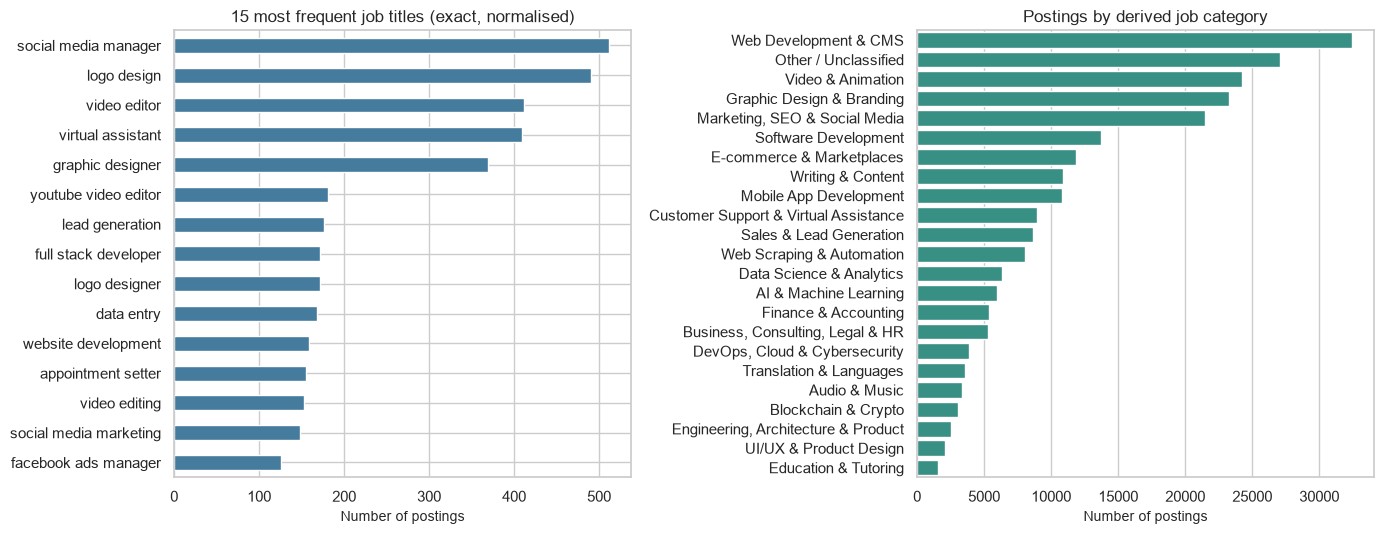

200,491 distinct normalised titles for 244,291 postings -> titles are long-tailed; the 15 most common cover only 1.6% of postings.


In [16]:
top_titles = jobs["title_norm"].value_counts().head(15)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
top_titles.sort_values().plot.barh(ax=axes[0], color="#457b9d")
axes[0].set_title("15 most frequent job titles (exact, normalised)")
axes[0].set_xlabel("Number of postings"); axes[0].set_ylabel("")
cat_counts = jobs["category"].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, ax=axes[1], color="#2a9d8f")
axes[1].set_title("Postings by derived job category")
axes[1].set_xlabel("Number of postings"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()
n_unique_titles = jobs["title_norm"].nunique()
print(f"{n_unique_titles:,} distinct normalised titles for {len(jobs):,} postings -> titles are long-tailed; "
      f"the 15 most common cover only {top_titles.sum() / len(jobs):.1%} of postings.")

**Interpretation.** Demand is dominated by creative/digital work (web development, design, video, marketing). The
exact-title ranking shows how fragmented titles are (generic titles like *Social Media Manager* or *Video Editor* repeat, but
most titles are unique) — this is why categories derived from keywords are more useful than raw titles.

### 5.2 Postings by country (client location)
`country` is the **client's** country. Upwork is a remote marketplace, so it says where demand comes from - not where the work is performed.

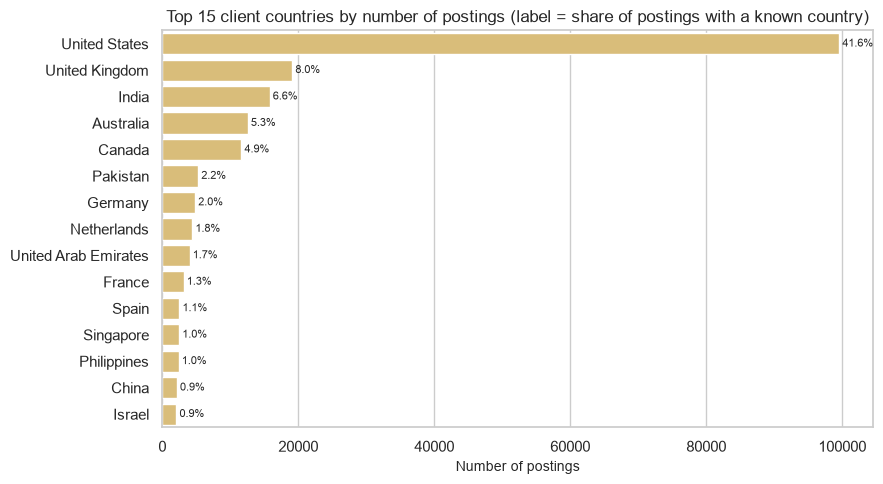

Top 5 countries account for 66.4% of postings with a country; 212 countries appear in total.


In [17]:
ctry = jobs["country"].value_counts()
top_c = ctry.head(15)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top_c.values, y=top_c.index, ax=ax, color="#e9c46a")
for i, v in enumerate(top_c.values):
    ax.text(v, i, f" {v / ctry.sum():.1%}", va="center", fontsize=8)
ax.set_title("Top 15 client countries by number of postings (label = share of postings with a known country)")
ax.set_xlabel("Number of postings"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print(f"Top 5 countries account for {ctry.head(5).sum() / ctry.sum():.1%} of postings with a country; "
      f"{len(ctry)} countries appear in total.")

### 5.3 Salary distributions and differences between categories
Pay amounts are heavily right-skewed, so histograms use a **log scale** and comparisons use **medians**.

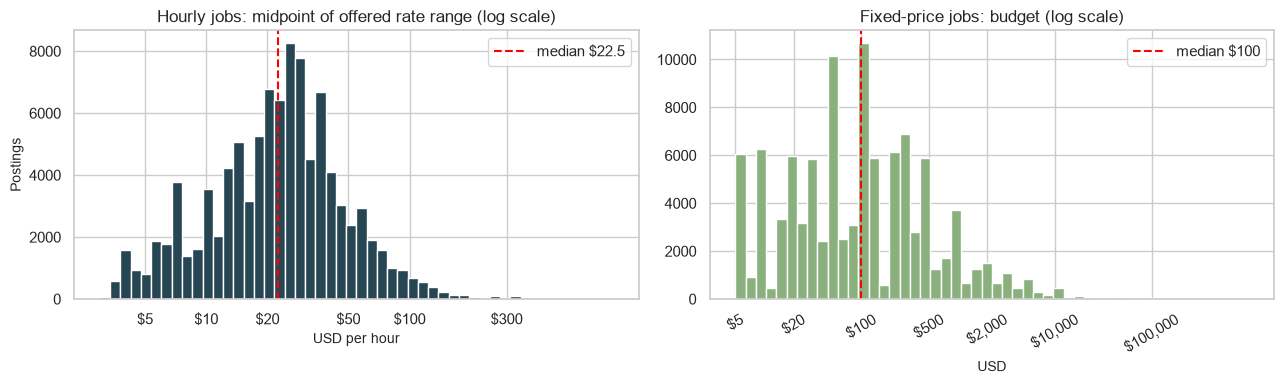

Note the spikes at round numbers ($5, $10, $20, $50, $100 ...): clients anchor on round figures.


In [18]:
hourly = jobs[jobs["hourly_mid_usd"].notna()]
fixed = jobs[jobs["fixed_budget_usd"].notna()]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.log10(hourly["hourly_mid_usd"]), bins=50, color="#264653")
ticks = [5, 10, 20, 50, 100, 300]
axes[0].set_xticks(np.log10(ticks)); axes[0].set_xticklabels([f"${t}" for t in ticks])
axes[0].axvline(np.log10(hourly["hourly_mid_usd"].median()), color="red", ls="--", label=f"median ${hourly['hourly_mid_usd'].median():.1f}")
axes[0].set_title("Hourly jobs: midpoint of offered rate range (log scale)"); axes[0].set_xlabel("USD per hour"); axes[0].set_ylabel("Postings"); axes[0].legend()
axes[1].hist(np.log10(fixed["fixed_budget_usd"]), bins=50, color="#8ab17d")
ticks = [5, 20, 100, 500, 2000, 10000, 100000]
axes[1].set_xticks(np.log10(ticks)); axes[1].set_xticklabels([f"${t:,}" for t in ticks], rotation=30)
axes[1].axvline(np.log10(fixed["fixed_budget_usd"].median()), color="red", ls="--", label=f"median ${fixed['fixed_budget_usd'].median():,.0f}")
axes[1].set_title("Fixed-price jobs: budget (log scale)"); axes[1].set_xlabel("USD"); axes[1].legend()
plt.tight_layout(); plt.show()
print("Note the spikes at round numbers ($5, $10, $20, $50, $100 ...): clients anchor on round figures.")

,n_hourly,median_hourly_usd,p25_hourly_usd,p75_hourly_usd,n_fixed,median_fixed_usd,p25_fixed_usd,p75_fixed_usd
category,,,,,,,,
Blockchain & Crypto,1553,37.50,25.00,57.50,1159,300.00,50.00,"1,200.00"
"Business, Consulting, Legal & HR",2566,33.25,16.50,65.00,1532,200.00,50.00,500.00
"DevOps, Cloud & Cybersecurity",1796,32.50,20.00,49.50,1448,100.00,30.00,261.25
UI/UX & Product Design,877,28.50,20.00,37.50,906,100.00,30.00,300.00
AI & Machine Learning,2444,27.50,17.50,40.00,2507,150.00,50.00,500.00
Finance & Accounting,2851,27.50,14.25,52.50,1478,122.50,50.00,300.00
"Engineering, Architecture & Product",960,27.00,20.00,45.00,1023,100.00,40.00,500.00
Writing & Content,4176,26.00,15.00,36.50,5091,100.00,30.00,360.00
Software Development,5251,25.00,17.50,37.50,6166,100.00,30.00,350.00


Highest median hourly rate : Blockchain & Crypto ($37.5, n=1,553); Business, Consulting, Legal & HR ($33.2, n=2,566); DevOps, Cloud & Cybersecurity ($32.5, n=1,796)
Lowest median hourly rate  : Marketing, SEO & Social Media ($17.5, n=10,133); Customer Support & Virtual Assistance ($10.0, n=4,672); Sales & Lead Generation ($10.0, n=3,652)


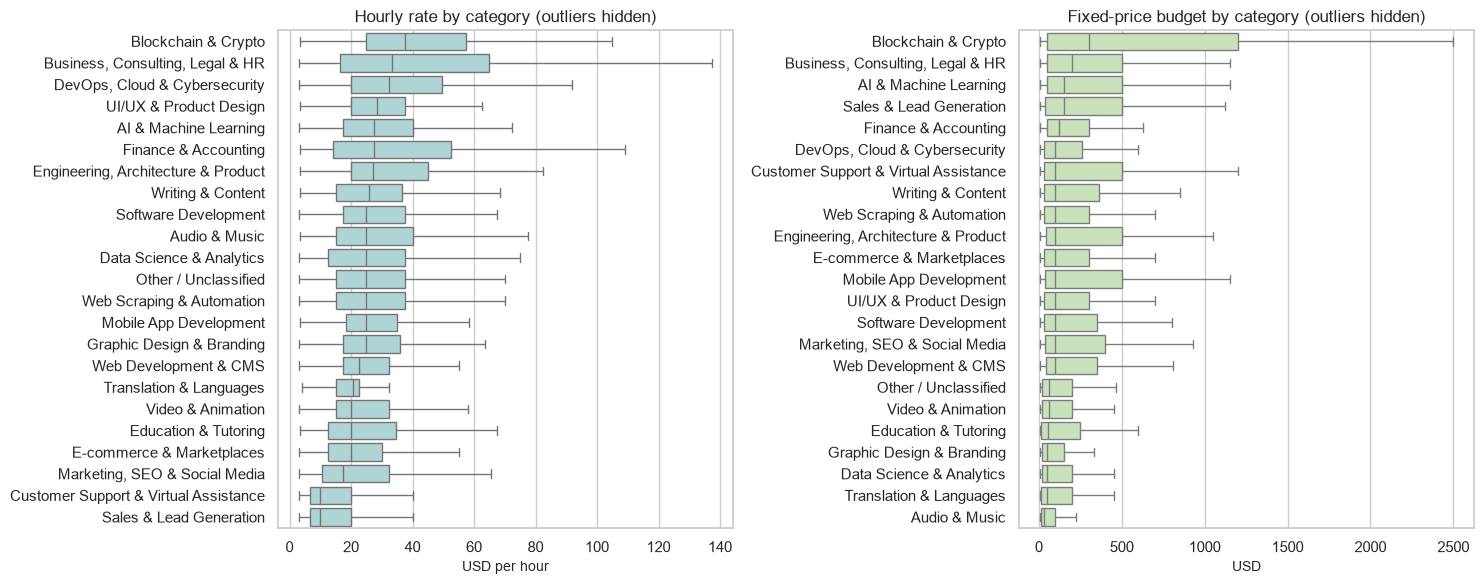

In [19]:
def salary_by_group(data, value, group, min_n=500):
    """Median, quartiles and count of `value` per group (groups with fewer than min_n rows are dropped)."""
    g = data.groupby(group)[value].agg(n="size", median="median", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75))
    return g[g["n"] >= min_n].sort_values("median", ascending=False)

by_cat_h = salary_by_group(hourly, "hourly_mid_usd", "category")
by_cat_f = salary_by_group(fixed, "fixed_budget_usd", "category")
display(by_cat_h.rename(columns=lambda c: c + "_hourly_usd" if c != "n" else "n_hourly").join(
    by_cat_f.rename(columns=lambda c: c + "_fixed_usd" if c != "n" else "n_fixed")))

hi, lo = by_cat_h.head(3), by_cat_h.tail(3)
print("Highest median hourly rate :", "; ".join(f"{i} (${v:.1f}, n={n:,})" for i, v, n in zip(hi.index, hi["median"], hi["n"])))
print("Lowest median hourly rate  :", "; ".join(f"{i} (${v:.1f}, n={n:,})" for i, v, n in zip(lo.index, lo["median"], lo["n"])))
order_h = by_cat_h.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=False)
sns.boxplot(data=hourly[hourly["category"].isin(order_h)], y="category", x="hourly_mid_usd", order=order_h, ax=axes[0],
            showfliers=False, color="#a8dadc")
axes[0].set_title("Hourly rate by category (outliers hidden)"); axes[0].set_xlabel("USD per hour"); axes[0].set_ylabel("")
order_f = by_cat_f.index.tolist()
sns.boxplot(data=fixed[fixed["category"].isin(order_f)], y="category", x="fixed_budget_usd", order=order_f, ax=axes[1],
            showfliers=False, color="#c7e9b4")
axes[1].set_title("Fixed-price budget by category (outliers hidden)"); axes[1].set_xlabel("USD"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Interpretation.** The printed ranking below the table is computed from the data (it is not hand-written). Differences between categories
in the *median* are modest compared with the spread *inside* each category (look at the width of the boxes): knowing the category tells you
something about pay, but far from everything. For fixed-price work, budgets are even more dispersed (a $5 micro-task and a $100,000 build can sit
in the same category).

### 5.4 Employment types and experience levels
* **Employment type** - the only real field is *hourly vs fixed price*.
* **Experience level** - the dataset has **no** such column. As a *weak proxy* we flag titles containing words such as
  *senior/expert* or *junior/beginner*. This reflects how the client **wrote the title**, not the required experience.

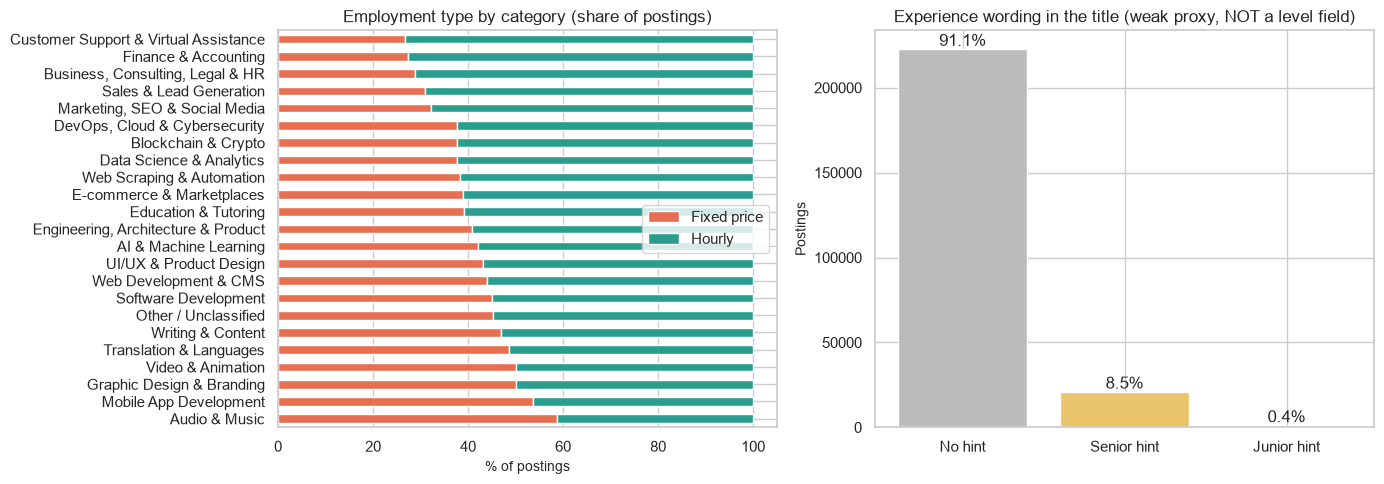

Hourly share overall: 57.6%. Hourly postings with a stated rate range: 70.1%.


,n_postings_with_hint,median_hourly_usd
experience_hint,,
Junior hint,977,22.50
Senior hint,20759,26.50


In [20]:
et = pd.crosstab(jobs["category"], jobs["pay_type"], normalize="index") * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
et.sort_values("Hourly").plot.barh(stacked=True, ax=axes[0], color=["#e76f51", "#2a9d8f"])
axes[0].set_title("Employment type by category (share of postings)"); axes[0].set_xlabel("% of postings"); axes[0].set_ylabel("")
axes[0].legend(title="")
hint = jobs["experience_hint"].value_counts()
axes[1].bar(hint.index, hint.values, color=["#bbb", "#e9c46a", "#264653"])
for i, v in enumerate(hint.values):
    axes[1].text(i, v, f"{v / len(jobs):.1%}", ha="center", va="bottom")
axes[1].set_title("Experience wording in the title (weak proxy, NOT a level field)"); axes[1].set_ylabel("Postings")
plt.tight_layout(); plt.show()
print(f"Hourly share overall: {(jobs['pay_type'] == 'Hourly').mean():.1%}. "
      f"Hourly postings with a stated rate range: {hourly.shape[0] / (jobs['pay_type'] == 'Hourly').sum():.1%}.")
senior = jobs[jobs["experience_hint"] != "No hint"].groupby("experience_hint")["hourly_mid_usd"].agg(["size", "median"])
display(senior.rename(columns={"size": "n_postings_with_hint", "median": "median_hourly_usd"}))

### 5.5 Remote, hybrid and on-site (first look)
Every Upwork posting is a remote freelance engagement, so **remote/hybrid/on-site cannot be measured from structured fields**.
The only available signal is whether the *title text itself* mentions it. This is explored properly in **Task 7**.

In [21]:
wm = jobs["work_mode_signal"].value_counts()
display(wm.to_frame("postings").assign(share_pct=lambda d: 100 * d["postings"] / d["postings"].sum()))

,postings,share_pct
work_mode_signal,,
No mention,242691,99.35
Remote mentioned,1359,0.56
On-site mentioned,208,0.09
Hybrid mentioned,33,0.01


### 5.6 Posting trends by month and year
The file spans Nov 2023 – Mar 2024 on paper, but real coverage is **mid-Feb to 24 Mar 2024**. *No full calendar month and no
full year exists*, so true month-over-month or year-over-year growth **cannot** be computed. Below we show the honest picture.

,month,calendar_days,days_with_any_data,complete_days,coverage_pct,total_postings_all_days,status
0,2023-11,30,1,0,0.00,1,sparse
1,2023-12,31,10,0,0.00,10,sparse
2,2024-01,31,25,0,0.00,96,sparse
3,2024-02,29,29,12,41.40,101686,partial
4,2024-03,31,24,23,74.20,142498,partial


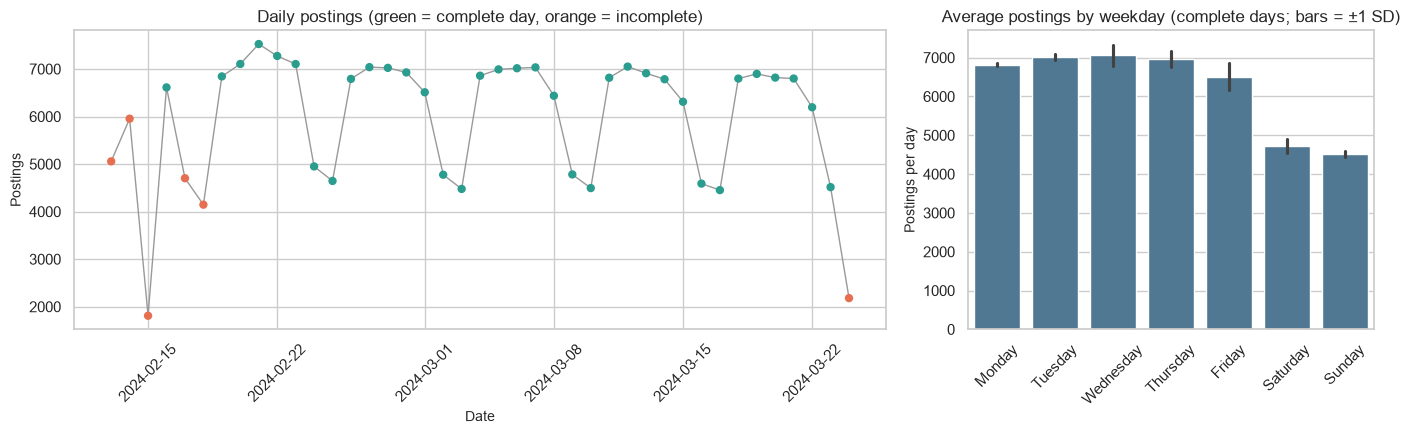

Weekend volume is 33% lower than weekdays -> a strong weekly cycle that any forecast must respect.


In [22]:
import reporting as rp
month_cov = rp.month_coverage(jobs)
display(month_cov)

daily = jobs.groupby("date").size().rename("postings").to_frame().join(coverage.set_index("date")["is_complete"])
recent = daily[daily.index >= "2024-02-13"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(recent.index, recent["postings"], color="#999", lw=1)
axes[0].scatter(recent.index, recent["postings"], c=np.where(recent["is_complete"], "#2a9d8f", "#e76f51"), s=25, zorder=3)
axes[0].set_title("Daily postings (green = complete day, orange = incomplete)"); axes[0].set_xlabel("Date"); axes[0].set_ylabel("Postings")
axes[0].tick_params(axis="x", rotation=45)
wd = core.groupby(["date", "weekday"]).size().reset_index(name="n")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.barplot(data=wd, x="weekday", y="n", order=order, ax=axes[1], color="#457b9d", errorbar="sd")
axes[1].set_title("Average postings by weekday (complete days; bars = ±1 SD)"); axes[1].set_xlabel(""); axes[1].set_ylabel("Postings per day")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
wk = wd.groupby("weekday")["n"].mean().reindex(order)
print(f"Weekend volume is {1 - wk[['Saturday', 'Sunday']].mean() / wk[order[:5]].mean():.0%} lower than weekdays -> "
      "a strong weekly cycle that any forecast must respect.")

**Interpretation.** There is a stable weekly rhythm (busy Mon–Fri, quiet weekends). Because the *monthly* totals depend on how many days were
captured, February and March raw counts must not be compared directly; later sections therefore use *postings per complete day*.
Annual seasonality (e.g. January hiring peaks) cannot be seen in 5 weeks of data.

## 6. Do job-title keywords go together with offered salary?

### 6.1 Keyword extraction

In [23]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

def keyword_matrix(data, min_count, max_features=None):
    """Binary document-term matrix from the pre-extracted title tokens (stop-words already removed)."""
    cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, binary=True,
                         min_df=min_count, max_features=max_features)
    X = cv.fit_transform(data["title_tokens"].fillna("")).tocsc()
    return X, np.array(cv.get_feature_names_out())

X_demo, vocab_demo = keyword_matrix(jobs, min_count=5000, max_features=20)
print("Most frequent title keywords (after stop-word removal):", ", ".join(vocab_demo))

Most frequent title keywords (after stop-word removal): app, assistant, business, content, data, design, designer, developer, editor, google, manager, marketing, media, social, specialist, video, web, website, wordpress, youtube


### 6.2 Keyword vs pay: Mann–Whitney tests with effect sizes

In [24]:
def keyword_effects(data, value_col, min_count=MIN_N_KEYWORD, top_k=120):
    """For each frequent keyword compare pay WITH vs WITHOUT it (Mann-Whitney U, rank-biserial r, ratio of medians)."""
    data = data[data[value_col].notna()].reset_index(drop=True)
    X, vocab = keyword_matrix(data, min_count, max_features=top_k)
    y = data[value_col].to_numpy()
    rows = []
    for j, word in enumerate(vocab):
        has = X[:, j].toarray().ravel() > 0
        a, b = y[has], y[~has]
        u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        rows.append({"keyword": word, "n_with": int(has.sum()), "median_with": np.median(a), "median_without": np.median(b),
                     "median_ratio": np.median(a) / np.median(b), "rank_biserial_r": 2 * u / (len(a) * len(b)) - 1, "p_value": p})
    out = pd.DataFrame(rows)
    out["q_value_BH"] = stats.false_discovery_control(out["p_value"].clip(lower=1e-300), method="bh")
    out["meaningful"] = (out["q_value_BH"] < ALPHA) & (out["rank_biserial_r"].abs() >= 0.15)
    return out.sort_values("rank_biserial_r", ascending=False).reset_index(drop=True), data, X, vocab

kw_h, hourly_d, Xh, vocab_h = keyword_effects(jobs, "hourly_mid_usd")
kw_f, fixed_d, Xf, vocab_f = keyword_effects(jobs, "fixed_budget_usd")
print(f"Hourly : {len(kw_h)} keywords tested, {int(kw_h['meaningful'].sum())} meaningful  | sample = {len(hourly_d):,} postings")
print(f"Fixed  : {len(kw_f)} keywords tested, {int(kw_f['meaningful'].sum())} meaningful  | sample = {len(fixed_d):,} postings")
show = ["keyword", "n_with", "median_with", "median_without", "median_ratio", "rank_biserial_r", "q_value_BH"]
print("\nHOURLY — keywords associated with HIGHER rates")
display(kw_h[show].head(8))
print("HOURLY — keywords associated with LOWER rates")
display(kw_h[show].tail(8).iloc[::-1])

Hourly : 120 keywords tested, 52 meaningful  | sample = 98,541 postings
Fixed  : 120 keywords tested, 42 meaningful  | sample = 103,696 postings

HOURLY — keywords associated with HIGHER rates


,keyword,n_with,median_with,median_without,median_ratio,rank_biserial_r,q_value_BH
0,tax,634,50.00,22.50,2.22,0.47,0.00
1,consultant,883,40.00,22.50,1.78,0.46,0.00
2,financial,550,37.50,22.50,1.67,0.34,0.00
3,senior,917,32.50,22.50,1.44,0.28,0.00
4,engineer,1497,32.50,22.50,1.44,0.26,0.00
5,system,546,30.00,22.50,1.33,0.26,0.00
6,custom,688,29.50,22.50,1.31,0.22,0.00
7,copywriter,605,30.00,22.50,1.33,0.21,0.00


HOURLY — keywords associated with LOWER rates


,keyword,n_with,median_with,median_without,median_ratio,rank_biserial_r,q_value_BH
119,va,670,6.50,22.50,0.29,-0.75,0.00
118,virtual,2393,7.50,23.00,0.33,-0.61,0.00
117,assistant,3834,9.00,24.00,0.38,-0.58,0.00
116,appointment,726,8.00,22.50,0.36,-0.53,0.00
115,setter,592,8.50,22.50,0.38,-0.50,0.00
114,cold,951,8.50,22.50,0.38,-0.50,0.00
113,generation,1013,10.00,22.50,0.44,-0.48,0.00
112,entry,843,10.00,22.50,0.44,-0.46,0.00


In [25]:
print("FIXED PRICE — keywords associated with HIGHER budgets")
display(kw_f[show].head(8))
print("FIXED PRICE — keywords associated with LOWER budgets")
display(kw_f[show].tail(8).iloc[::-1])

FIXED PRICE — keywords associated with HIGHER budgets


,keyword,n_with,median_with,median_without,median_ratio,rank_biserial_r,q_value_BH
0,development,2203,300.00,100.00,3.00,0.39,0.00
1,engineer,645,300.00,100.00,3.00,0.38,0.00
2,sales,1398,250.00,100.00,2.50,0.35,0.00
3,ios,679,250.00,100.00,2.50,0.32,0.00
4,platform,668,300.00,100.00,3.00,0.30,0.00
5,software,644,250.00,100.00,2.50,0.30,0.00
6,stack,598,250.00,100.00,2.50,0.29,0.00
7,agency,800,200.00,100.00,2.00,0.29,0.00


FIXED PRICE — keywords associated with LOWER budgets


,keyword,n_with,median_with,median_without,median_ratio,rank_biserial_r,q_value_BH
119,recording,702,15.00,100.00,0.15,-0.56,0.00
118,thumbnail,611,20.00,100.00,0.20,-0.40,0.00
117,edit,846,30.00,100.00,0.30,-0.37,0.00
116,fix,1038,30.00,100.00,0.30,-0.35,0.00
115,image,934,30.00,100.00,0.30,-0.33,0.00
114,file,694,30.00,100.00,0.30,-0.31,0.00
113,photo,615,35.00,100.00,0.35,-0.30,0.00
112,pdf,674,40.00,100.00,0.40,-0.27,0.00


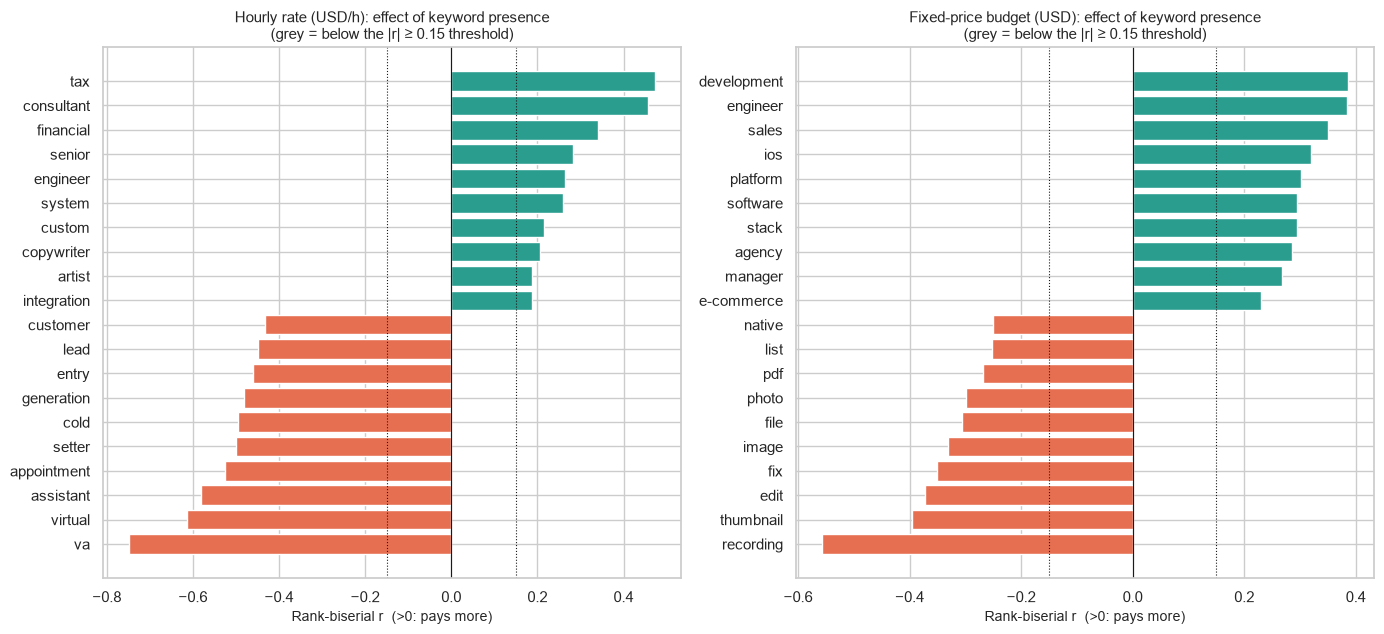

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, kw, title in zip(axes, (kw_h, kw_f), ("Hourly rate (USD/h)", "Fixed-price budget (USD)")):
    sel = pd.concat([kw.head(10), kw.tail(10)]).drop_duplicates("keyword").sort_values("rank_biserial_r")
    colors = np.where(sel["meaningful"], np.where(sel["rank_biserial_r"] > 0, "#2a9d8f", "#e76f51"), "#bbbbbb")
    ax.barh(sel["keyword"], sel["rank_biserial_r"], color=colors)
    ax.axvline(0, color="k", lw=0.8); ax.axvline(0.15, color="k", ls=":", lw=0.8); ax.axvline(-0.15, color="k", ls=":", lw=0.8)
    ax.set_title(f"{title}: effect of keyword presence\n(grey = below the |r| ≥ 0.15 threshold)", fontsize=11); ax.set_xlabel("Rank-biserial r  (>0: pays more)")
plt.tight_layout(); plt.show()

**How to read this.** A bar of *r* = +0.20 means: if you pick one posting with the keyword and one without at random, the one with the
keyword pays more about 60 % of the time (probability = (r+1)/2). Grey bars are statistically detectable but practically small.

### 6.3 Compare distributions across keyword *groups* (job categories)
A single keyword is noisy; our derived **categories** are groups of keywords. The **Kruskal–Wallis H test** asks whether *any* category
differs; ε² (epsilon-squared) says how much of the rank variation the categories explain; η² is the same idea on the log scale (ANOVA-style).

In [27]:
def group_test(data, value_col, group_col="category", min_n=500):
    d = data[data[value_col].notna()]
    d = d[d.groupby(group_col)[value_col].transform("size") >= min_n]
    groups = [g[value_col].to_numpy() for _, g in d.groupby(group_col)]
    H, p = stats.kruskal(*groups)
    k, n = len(groups), len(d)
    logv = np.log(d[value_col])
    ss_between = sum(len(g) * (np.log(g).mean() - logv.mean()) ** 2 for g in groups)
    return {"pay_measure": value_col, "n": n, "k_groups": k, "H": H, "p_value": p,
            "epsilon_squared": (H - k + 1) / (n - k), "eta_squared_log": ss_between / ((logv - logv.mean()) ** 2).sum()}

display(pd.DataFrame([group_test(jobs, "hourly_mid_usd"), group_test(jobs, "fixed_budget_usd")]))

,pay_measure,n,k_groups,H,p_value,epsilon_squared,eta_squared_log
0,hourly_mid_usd,98541,23,"8,619.49",0.00,0.09,0.09
1,fixed_budget_usd,103696,23,"3,605.57",0.00,0.03,0.04


**Interpretation.** Both tests are highly significant (as expected with large *n*), but ε² and η² are small: the category explains
under 10 % of pay variation (ε² ≈ 0.09 for hourly rates, ≈ 0.04 for fixed budgets in this run). Statistically real, practically modest.

### 6.4 Correlation - when it is (and is not) appropriate
**Why a plain correlation coefficient is the wrong tool for keywords.** A keyword is *categorical* (present/absent) and has no order or distance,
so Pearson's *r* between "contains *wordpress*" and "salary" is just a rescaled difference of means. It (a) is driven by how *common* the
keyword is (a rare keyword can never reach a large |r|), (b) is dominated by extreme prices, and (c) ignores that keywords overlap
(*"senior wordpress developer"* contains three). Below we show (a)–(b) concretely, then report correlations only for variables where they are meaningful.

In [28]:
demo = []
for word in list(kw_f.sort_values("n_with", ascending=False)["keyword"].head(4)):
    has = (Xf[:, list(vocab_f).index(word)].toarray().ravel() > 0).astype(float)
    y = fixed_d["fixed_budget_usd"].to_numpy()
    demo.append({"keyword": word, "prevalence": has.mean(),
                 "Pearson r (raw $)": np.corrcoef(has, y)[0, 1],
                 "Pearson r (log $)": np.corrcoef(has, np.log(y))[0, 1],
                 "Spearman rho": stats.spearmanr(has, y)[0]})
display(pd.DataFrame(demo))
print("-> the same keyword gives different 'correlations' depending on the (arbitrary) price scale; raw-$ values are near zero because a few "
      "huge budgets dominate the variance.")

,keyword,prevalence,Pearson r (raw $),Pearson r (log $),Spearman rho
0,website,0.08,-0.01,0.05,0.06
1,video,0.07,-0.01,-0.04,-0.04
2,design,0.06,-0.01,-0.01,-0.01
3,developer,0.06,0.01,0.09,0.09


-> the same keyword gives different 'correlations' depending on the (arbitrary) price scale; raw-$ values are near zero because a few huge budgets dominate the variance.


In [29]:
# Meaningful correlations: NUMERIC / ORDINAL predictors vs pay. Title length (words) is a genuine numeric variable.
for name, d, col in (("hourly", hourly_d, "hourly_mid_usd"), ("fixed", fixed_d, "fixed_budget_usd")):
    n_words = d["title_tokens"].fillna("").str.split().str.len()
    rho, p = stats.spearmanr(n_words, d[col])
    print(f"Spearman correlation, number of title keywords vs {name} pay: rho = {rho:+.3f} (p = {p:.1e}, n = {len(d):,})")

Spearman correlation, number of title keywords vs hourly pay: rho = +0.020 (p = 1.6e-10, n = 98,541)
Spearman correlation, number of title keywords vs fixed pay: rho = +0.059 (p = 5.5e-80, n = 103,696)


### 6.5 Joint model: all keywords at once (regularised regression)
To handle overlapping keywords we fit a **Ridge regression** of *log pay* on 0/1 keyword indicators (the 300 most frequent keywords). Ridge shrinks
unstable coefficients; the penalty is chosen by cross-validation on the **training** part only. We report **R² on a held-out 20 %** (random split,
seed fixed- appropriate here because we are not forecasting the future). An R² near 0 means keywords alone barely predict pay.

In [30]:
def ridge_keyword_model(data, value_col, top_k=300):
    X, vocab = keyword_matrix(data, min_count=MIN_N_KEYWORD // 3, max_features=top_k)
    y = np.log(data[value_col].to_numpy())
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
    # penalty chosen by 3-fold CV on the TRAINING part only (RidgeCV is avoided: it mishandles sparse input)
    search = GridSearchCV(Ridge(), {"alpha": [1, 10, 100, 1000]}, cv=3, scoring="r2").fit(X_tr, y_tr)
    model = search.best_estimator_
    pred = model.predict(X_te)
    coef = pd.Series(model.coef_, index=vocab)
    res = {"pay_measure": value_col, "n_keywords": len(vocab), "best_alpha": search.best_params_["alpha"],
           "R2_test": r2_score(y_te, pred), "R2_baseline_mean": r2_score(y_te, np.full_like(y_te, y_tr.mean()))}
    return res, coef

res_h, coef_h = ridge_keyword_model(hourly_d, "hourly_mid_usd")
res_f, coef_f = ridge_keyword_model(fixed_d, "fixed_budget_usd")
display(pd.DataFrame([res_h, res_f]))
coef_tbl = pd.concat({
    "hourly: higher": coef_h.nlargest(6).apply(lambda c: np.expm1(c) * 100).round(1),
    "hourly: lower": coef_h.nsmallest(6).apply(lambda c: np.expm1(c) * 100).round(1),
    "fixed: higher": coef_f.nlargest(6).apply(lambda c: np.expm1(c) * 100).round(1),
    "fixed: lower": coef_f.nsmallest(6).apply(lambda c: np.expm1(c) * 100).round(1)}, axis=1)
print("Ridge coefficients converted to '% difference in pay, other keywords held constant' (shrunken estimates):")
display(coef_tbl)

,pay_measure,n_keywords,best_alpha,R2_test,R2_baseline_mean
0,hourly_mid_usd,300,10,0.19,-0.00
1,fixed_budget_usd,300,10,0.13,-0.00


Ridge coefficients converted to '% difference in pay, other keywords held constant' (shrunken estimates):


,hourly: higher,hourly: lower,fixed: higher,fixed: lower
videographer,79.80,NaN,247.40,NaN
tax,71.90,NaN,NaN,NaN
consultation,69.20,NaN,NaN,NaN
legal,63.80,NaN,NaN,NaN
consultant,55.10,NaN,NaN,NaN
nft,49.20,NaN,NaN,NaN
va,NaN,-60.20,NaN,NaN
onlyfans,NaN,-53.10,NaN,NaN
assistant,NaN,-44.10,NaN,NaN
list,NaN,-40.90,NaN,NaN


In [31]:
# Robustness: do conclusions survive removing flagged pay outliers?
rob = []
for name, d, kw in (("hourly", jobs[jobs["pay_outlier"] == "normal"], kw_h), ("fixed", jobs[jobs["pay_outlier"] == "normal"], kw_f)):
    col = "hourly_mid_usd" if name == "hourly" else "fixed_budget_usd"
    kw2, *_ = keyword_effects(d, col)
    merged = kw[["keyword", "rank_biserial_r"]].merge(kw2[["keyword", "rank_biserial_r"]], on="keyword", suffixes=("_all", "_no_outliers"))
    rob.append({"pay_measure": name, "n_keywords": len(merged),
                "Spearman(effect sizes, with vs without outliers)": stats.spearmanr(merged.iloc[:, 1], merged.iloc[:, 2])[0]})
display(pd.DataFrame(rob))

,pay_measure,n_keywords,"Spearman(effect sizes, with vs without outliers)"
0,hourly,118,1.00
1,fixed,120,1.00


## 7. Emerging job categories

In [32]:
core_wk = core.copy()
days_per_week = core_wk.groupby("week_start")["date"].nunique()
full_weeks = days_per_week[days_per_week == 7].index.sort_values()
partial_weeks = days_per_week[days_per_week < 7].index
print("Full weeks used for growth:", [str(w.date()) for w in full_weeks])
print("Partial week(s) shown only:", {str(w.date()): int(days_per_week[w]) for w in partial_weeks})

weekly = core_wk.groupby(["week_start", "category"]).size().unstack(fill_value=0)
weekly_total = weekly.sum(axis=1)
W = weekly.loc[full_weeks]
share = W.div(W.sum(axis=1), axis=0) * 100

first, last = full_weeks[0], full_weeks[-1]
rows = []
for cat in W.columns:
    a, b = W.loc[first, cat], W.loc[last, cat]
    n1, n2 = W.loc[first].sum(), W.loc[last].sum()
    p1, p2 = a / n1, b / n2
    pooled = (a + b) / (n1 + n2)
    z = (p2 - p1) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2)) if 0 < pooled < 1 else np.nan
    rows.append({"category": cat, f"postings_week1": a, "postings_last_week": b, "abs_growth": b - a,
                 "pct_growth": 100 * (b - a) / a if a else np.nan,
                 "share_week1_%": 100 * p1, "share_last_%": 100 * p2, "share_change_rel_%": 100 * (p2 - p1) / p1 if p1 else np.nan,
                 "avg_weekly_growth_%": 100 * ((b / a) ** (1 / (len(full_weeks) - 1)) - 1) if a and b else np.nan,
                 "z": z, "p_value": 2 * stats.norm.sf(abs(z)) if np.isfinite(z) else np.nan,
                 "first_half_share": share.loc[full_weeks[:2], cat].mean(), "last_half_share": share.loc[full_weeks[-2:], cat].mean()})
growth = pd.DataFrame(rows)
growth["q_value_BH"] = stats.false_discovery_control(growth["p_value"].fillna(1).clip(lower=1e-300), method="bh")

def classify(r, min_n=150):
    if min(r["postings_week1"], r["postings_last_week"]) < min_n:
        return "Insufficient data"
    up = r["share_change_rel_%"] >= 10 and r["q_value_BH"] < ALPHA and r["last_half_share"] > r["first_half_share"]
    down = r["share_change_rel_%"] <= -10 and r["q_value_BH"] < ALPHA and r["last_half_share"] < r["first_half_share"]
    return "Candidate emerging" if up else "Declining" if down else "Stable"

growth["status"] = growth.apply(classify, axis=1)
growth = growth.sort_values("share_change_rel_%", ascending=False).reset_index(drop=True)
cols = ["category", "postings_week1", "postings_last_week", "abs_growth", "pct_growth", "share_week1_%", "share_last_%", "q_value_BH", "status"]
display(growth[cols])

Full weeks used for growth: ['2024-02-19', '2024-02-26', '2024-03-04', '2024-03-11']
Partial week(s) shown only: {'2024-03-18': 6}


,category,postings_week1,postings_last_week,abs_growth,pct_growth,share_week1_%,share_last_%,q_value_BH,status
0,Blockchain & Crypto,447,595,148,33.11,0.98,1.39,0.00,Candidate emerging
1,AI & Machine Learning,1006,1112,106,10.54,2.21,2.59,0.00,Candidate emerging
2,UI/UX & Product Design,365,383,18,4.93,0.80,0.89,0.28,Stable
3,"Marketing, SEO & Social Media",3779,3918,139,3.68,8.31,9.13,0.00,Stable
4,Video & Animation,4261,4412,151,3.54,9.38,10.28,0.00,Stable
5,Web Scraping & Automation,1378,1411,33,2.39,3.03,3.29,0.08,Stable
6,Software Development,2446,2436,-10,-0.41,5.38,5.68,0.12,Stable
7,Web Development & CMS,5808,5782,-26,-0.45,12.78,13.47,0.01,Stable
8,Sales & Lead Generation,1573,1557,-16,-1.02,3.46,3.63,0.32,Stable
9,Mobile App Development,1975,1933,-42,-2.13,4.35,4.50,0.36,Stable


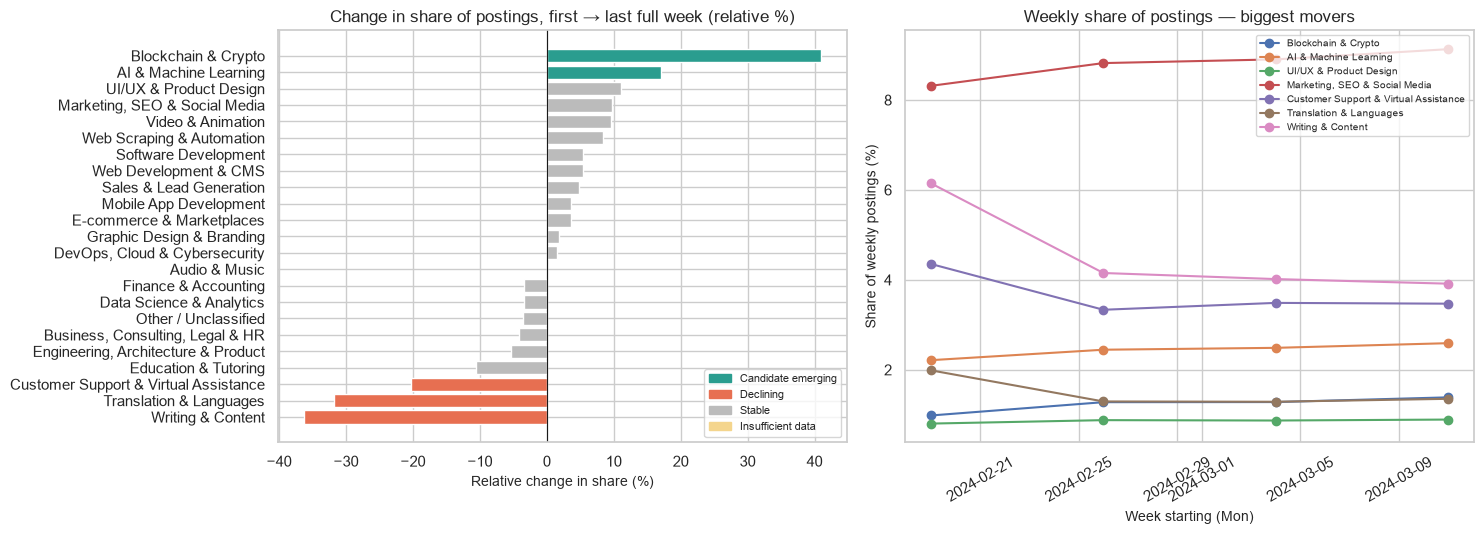

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
pal = {"Candidate emerging": "#2a9d8f", "Declining": "#e76f51", "Stable": "#bbbbbb", "Insufficient data": "#f4d58d"}
g = growth.sort_values("share_change_rel_%")
axes[0].barh(g["category"], g["share_change_rel_%"], color=g["status"].map(pal))
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title("Change in share of postings, first → last full week (relative %)")
axes[0].set_xlabel("Relative change in share (%)")
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=c, label=k) for k, c in pal.items()], loc="lower right", fontsize=8)
movers = pd.concat([growth.head(4), growth.tail(3)])["category"].tolist()
for c in movers:
    axes[1].plot(share.index, share[c], marker="o", label=c)
axes[1].set_title("Weekly share of postings — biggest movers"); axes[1].set_ylabel("Share of weekly postings (%)")
axes[1].set_xlabel("Week starting (Mon)"); axes[1].legend(fontsize=7, loc="best"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### 7.1 Monthly posting counts
February and March are both **partial**, so we show raw counts *and* postings per complete day. Percentage change between them is
provisional.

In [34]:
monthly = core_wk.groupby(["month", "category"]).size().unstack(0, fill_value=0)
ndays = core_wk.groupby("month")["date"].nunique()
per_day = monthly.div(ndays, axis=1)
mt = pd.concat({"postings": monthly, "per_complete_day": per_day}, axis=1)
mt[("change", "abs_per_day")] = per_day.iloc[:, -1] - per_day.iloc[:, 0]
mt[("change", "pct_per_day")] = 100 * mt[("change", "abs_per_day")] / per_day.iloc[:, 0]
display(mt.sort_values(("postings", monthly.columns[-1]), ascending=False).round(1))
print("Complete days per month in the core window:", ndays.to_dict(), "(neither month is complete -> % changes are PROVISIONAL)")

postings         per_complete_day  \
month                                  2024-02 2024-03          2024-02   
category                                                                  
Web Development & CMS                     9585   18811           871.40   
Other / Unclassified                      8239   15562           749.00   
Video & Animation                         6918   14286           628.90   
Graphic Design & Branding                 6895   13423           626.80   
Marketing, SEO & Social Media             6246   12521           567.80   
Software Development                      4041    7866           367.40   
E-commerce & Marketplaces                 3510    6843           319.10   
Mobile App Development                    3221    6193           292.80   
Writing & Content                         3921    5475           356.50   
Sales & Lead Generation                   2577    4983           234.30   
Customer Support & Virtual Assistance     2928    4863           266.20   
Web Scraping & Automation                 2350    4668           213.60   
Data Science & Analytics                  1903    3616           173.00   
AI & Machine Learning                     1648    3555           149.80   
Finance & Accounting                      1633    3100           148.50   
Business, Consulting, Legal & HR          1555    3068           141.40   
DevOps, Cloud & Cybersecurity             1124    2240           102.20   
Blockchain & Crypto                        770    1944            70.00   
Audio & Music                             1033    1928            93.90   
Translation & Languages                   1323    1779           120.30   
Engineering, Architecture & Product        751    1465            68.30   
UI/UX & Product Design                     614    1249            55.80   
Education & Tutoring                       447     880            40.60   

                                                   change              
month                                 2024-03 abs_per_day pct_per_day  
category                                                               
Web Development & CMS                  817.90      -53.50       -6.10  
Other / Unclassified                   676.60      -72.40       -9.70  
Video & Animation                      621.10       -7.80       -1.20  
Graphic Design & Branding              583.60      -43.20       -6.90  
Marketing, SEO & Social Media          544.40      -23.40       -4.10  
Software Development                   342.00      -25.40       -6.90  
E-commerce & Marketplaces              297.50      -21.60       -6.80  
Mobile App Development                 269.30      -23.60       -8.00  
Writing & Content                      238.00     -118.40      -33.20  
Sales & Lead Generation                216.70      -17.60       -7.50  
Customer Support & Virtual Assistance  211.40      -54.70      -20.60  
Web Scraping & Automation              203.00      -10.70       -5.00  
Data Science & Analytics               157.20      -15.80       -9.10  
AI & Machine Learning                  154.60        4.70        3.20  
Finance & Accounting                   134.80      -13.70       -9.20  
Business, Consulting, Legal & HR       133.40       -8.00       -5.60  
DevOps, Cloud & Cybersecurity           97.40       -4.80       -4.70  
Blockchain & Crypto                     84.50       14.50       20.70  
Audio & Music                           83.80      -10.10      -10.70  
Translation & Languages                 77.30      -42.90      -35.70  
Engineering, Architecture & Product     63.70       -4.60       -6.70  
UI/UX & Product Design                  54.30       -1.50       -2.70  
Education & Tutoring                    38.30       -2.40       -5.80

Complete days per month in the core window: {'2024-02': 11, '2024-03': 23} (neither month is complete -> % changes are PROVISIONAL)


### 7.2 Keyword-level emerging terms
Categories are coarse; new roles often appear as **new words** (a tool, a platform). We apply the same share test to individual title keywords
(≥ 150 postings in the last full week to avoid noise).

In [35]:
Xc, vocab_c = keyword_matrix(core_wk, min_count=300)
wk_idx = {w: (core_wk["week_start"].to_numpy() == np.datetime64(w)) for w in (first, last)}
n_first, n_last = wk_idx[first].sum(), wk_idx[last].sum()
c_first = np.asarray(Xc[wk_idx[first]].sum(axis=0)).ravel()
c_last = np.asarray(Xc[wk_idx[last]].sum(axis=0)).ravel()
kw_rows = []
for w, a, b in zip(vocab_c, c_first, c_last):
    if b < 150:
        continue
    p1, p2 = a / n_first, b / n_last
    pooled = (a + b) / (n_first + n_last)
    z = (p2 - p1) / np.sqrt(pooled * (1 - pooled) * (1 / n_first + 1 / n_last))
    kw_rows.append({"keyword": w, "postings_week1": int(a), "postings_last_week": int(b),
                    "pct_growth": 100 * (b - a) / a if a else np.inf, "p_value": 2 * stats.norm.sf(abs(z))})
kw_g = pd.DataFrame(kw_rows)
kw_g["q_value_BH"] = stats.false_discovery_control(kw_g["p_value"].clip(lower=1e-300), method="bh")
# the keyword's own total volume can move with the total number of postings, so we also report share growth:
kw_g["share_growth_%"] = 100 * ((kw_g["postings_last_week"] / n_last) / (kw_g["postings_week1"].clip(lower=1) / n_first) - 1)
sig = kw_g[(kw_g["q_value_BH"] < ALPHA) & (kw_g["share_growth_%"] > 0)].sort_values("share_growth_%", ascending=False)
print(f"{len(kw_g)} keywords tested; {len(sig)} grew significantly in share (q<0.05). Top 12:")
display(sig.head(12)[["keyword", "postings_week1", "postings_last_week", "share_growth_%", "q_value_BH"]])
dec = kw_g[(kw_g["q_value_BH"] < ALPHA) & (kw_g["share_growth_%"] < 0)].sort_values("share_growth_%").head(6)
print("Fastest-shrinking keywords:"); display(dec[["keyword", "postings_week1", "postings_last_week", "share_growth_%", "q_value_BH"]])

192 keywords tested; 14 grew significantly in share (q<0.05). Top 12:


,keyword,postings_week1,postings_last_week,share_growth_%,q_value_BH
47,crypto,126,200,68.10,0.00
134,recording,114,163,51.43,0.01
93,images,137,178,37.60,0.04
82,form,213,268,33.25,0.02
148,setter,191,239,32.52,0.03
18,appointment,277,333,27.32,0.03
76,figma,253,304,27.25,0.04
75,facebook,626,746,26.21,0.00
5,ads,844,960,20.46,0.00
8,ai,606,678,18.49,0.02


Fastest-shrinking keywords:


,keyword,postings_week1,postings_last_week,share_growth_%,q_value_BH
41,copy,397,172,-54.12,0.00
190,writing,449,203,-52.12,0.00
68,entry,633,288,-51.82,0.00
154,spanish,439,228,-45.00,0.00
169,translation,522,338,-31.43,0.00
189,writer,1204,819,-27.96,0.00


## 8. Average hourly rates across countries

In [36]:
hr = jobs[jobs["hourly_mid_usd"].notna() & jobs["country"].notna()]

def median_ci(x, conf=0.95):
    """Distribution-free CI for the median using binomial order statistics."""
    x = np.sort(np.asarray(x)); n = len(x)
    lo = int(stats.binom.ppf((1 - conf) / 2, n, 0.5)); hi = int(stats.binom.ppf(1 - (1 - conf) / 2, n, 0.5))
    return x[max(lo - 1, 0)], x[min(hi, n - 1)]

rows = []
for (country, iso), g in hr.groupby(["country", "country_iso3"]):
    v = g["hourly_mid_usd"].to_numpy()
    if len(v) < MIN_N_COUNTRY:
        continue
    lo, hi = median_ci(v)
    rows.append({"country": country, "country_iso3": iso, "n": len(v), "median_rate": np.median(v), "ci_low": lo, "ci_high": hi,
                 "mean_rate": v.mean(), "trimmed_mean_10pct": stats.trim_mean(v, 0.1), "p25": np.percentile(v, 25), "p75": np.percentile(v, 75)})
country_rates = pd.DataFrame(rows).sort_values("median_rate", ascending=False).reset_index(drop=True)
print(f"{len(country_rates)} countries have >= {MIN_N_COUNTRY} hourly postings with a stated rate "
      f"(covering {country_rates['n'].sum() / len(hr):.1%} of such postings).")
display(country_rates.head(12)[["country", "n", "median_rate", "ci_low", "ci_high", "mean_rate", "trimmed_mean_10pct"]])
print("Lowest medians:")
display(country_rates.tail(6)[["country", "n", "median_rate", "ci_low", "ci_high", "mean_rate"]])

big = country_rates[country_rates["n"] >= 100]
H, p = stats.kruskal(*[hr.loc[hr["country"] == c, "hourly_mid_usd"] for c in big["country"]])
eps2 = (H - len(big) + 1) / (big["n"].sum() - len(big))
print(f"Kruskal-Wallis across the {len(big)} countries with n>=100: H={H:,.0f}, p={p:.1e}, epsilon^2={eps2:.3f} "
      "(share of rank variation explained by client country)")

91 countries have >= 30 hourly postings with a stated rate (covering 99.3% of such postings).


,country,n,median_rate,ci_low,ci_high,mean_rate,trimmed_mean_10pct
0,Latvia,106,30.00,25.00,32.50,32.39,30.00
1,Oman,49,29.00,25.00,32.50,29.93,28.02
2,Vietnam,249,27.50,27.50,27.50,30.28,27.03
3,Moldova,40,26.50,16.50,30.00,27.69,24.78
4,Kenya,314,26.00,25.00,28.50,31.82,29.04
5,Morocco,139,25.00,22.50,26.00,27.38,25.17
6,Lithuania,156,25.00,20.00,26.00,29.18,24.89
7,Denmark,405,25.00,22.50,25.00,29.86,25.30
8,Albania,43,25.00,16.50,26.00,27.48,25.36
9,Bosnia and Herzegovina,37,25.00,18.00,30.00,28.65,24.61


Lowest medians:


,country,n,median_rate,ci_low,ci_high,mean_rate
85,Dominican Republic,54,15.25,11.00,20.50,19.86
86,Japan,245,15.00,12.00,17.50,22.02
87,Taiwan,52,15.00,10.00,17.50,15.98
88,Slovenia,113,14.50,10.00,20.00,21.99
89,Philippines,901,13.00,12.50,15.00,30.58
90,South Korea,270,10.00,10.00,10.00,15.44


Kruskal-Wallis across the 59 countries with n>=100: H=2,064, p=0.0e+00, epsilon^2=0.021 (share of rank variation explained by client country)


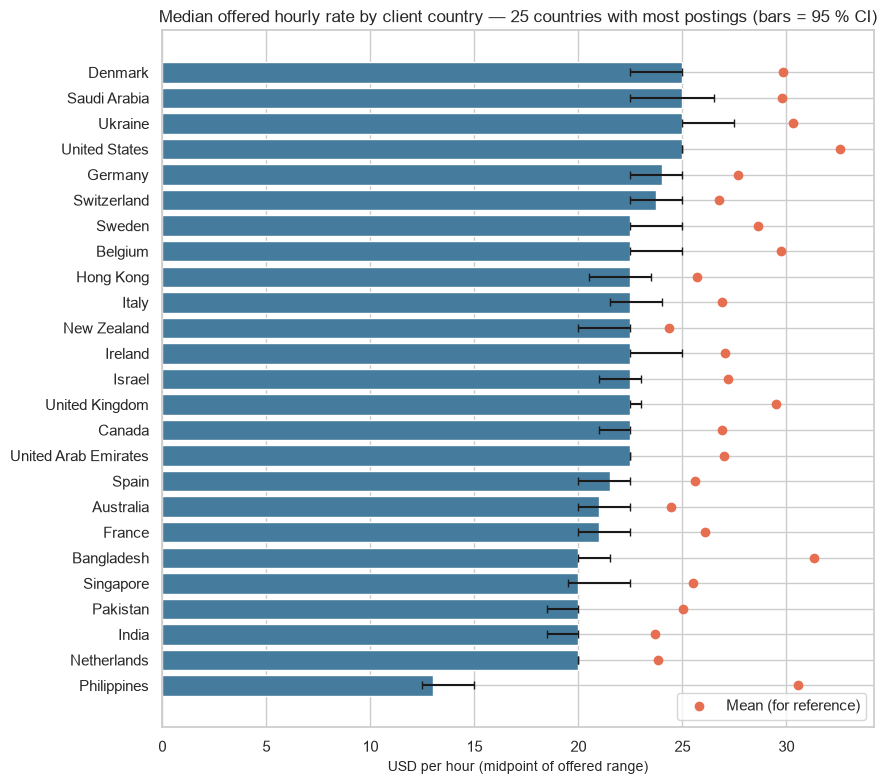

In [37]:
# Country-level bar chart: the 25 countries with most postings, sorted by median, with 95% CI
top25 = country_rates.sort_values("n", ascending=False).head(25).sort_values("median_rate")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top25["country"], top25["median_rate"], color="#457b9d",
        xerr=[top25["median_rate"] - top25["ci_low"], top25["ci_high"] - top25["median_rate"]], capsize=3)
ax.scatter(top25["mean_rate"], top25["country"], color="#e76f51", zorder=3, label="Mean (for reference)")
ax.set_title("Median offered hourly rate by client country — 25 countries with most postings (bars = 95 % CI)")
ax.set_xlabel("USD per hour (midpoint of offered range)"); ax.set_ylabel(""); ax.legend()
plt.tight_layout(); plt.show()

### 8.1 Interactive map (Plotly)

In [38]:
try:
    import plotly.express as px
except ImportError as exc:
    raise ImportError("Plotly is required for the interactive map: pip install plotly") from exc

fig_map = px.choropleth(country_rates, locations="country_iso3", color="median_rate", hover_name="country",
                        hover_data={"n": True, "ci_low": ":.1f", "ci_high": ":.1f", "mean_rate": ":.1f", "country_iso3": False},
                        color_continuous_scale="Viridis", range_color=(country_rates["median_rate"].quantile(.05), country_rates["median_rate"].quantile(.95)),
                        title="Median offered hourly rate (USD) by client country (countries with ≥ 30 hourly postings)",
                        labels={"median_rate": "Median USD/h", "n": "Postings", "ci_low": "95% CI low", "ci_high": "95% CI high", "mean_rate": "Mean USD/h"})
fig_map.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig_map.write_html(FIG_DIR / "hourly_rate_map.html", include_plotlyjs="cdn")
fig_map.show()
print("Saved:", (FIG_DIR / "hourly_rate_map.html").relative_to(ROOT))

Saved: outputs\figures\hourly_rate_map.html


### 8.2 Sensitivity checks -are the country differences an artefact?

,baseline,incl. lower-bound-only,no outliers
baseline,1.00,0.96,0.97
incl. lower-bound-only,0.96,1.00,0.95
no outliers,0.97,0.95,1.00


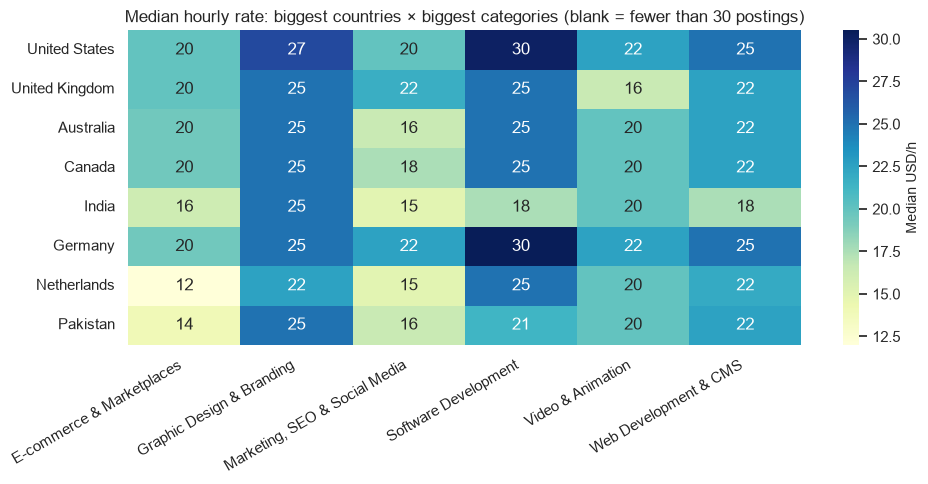

In [39]:
def country_medians(data, col):
    g = data[data[col].notna() & data["country"].notna()].groupby("country")[col].agg(["size", "median"])
    return g[g["size"] >= MIN_N_COUNTRY]["median"]

base_med = country_rates.set_index("country")["median_rate"]
alt = jobs.assign(alt_rate=jobs["hourly_mid_usd"].fillna(jobs["hourly_low_only_usd"]))
sens = pd.concat({"baseline": base_med,
                  "incl. lower-bound-only": country_medians(alt, "alt_rate"),
                  "no outliers": country_medians(jobs[jobs["pay_outlier"] == "normal"], "hourly_mid_usd")}, axis=1).dropna()
display(sens.corr(method="spearman").round(3))

top_ctry = hr["country"].value_counts().head(8).index
top_cat = hr[hr["category"] != jt.UNCLASSIFIED]["category"].value_counts().head(6).index
cell = hr[hr["country"].isin(top_ctry) & hr["category"].isin(top_cat)].groupby(["country", "category"])["hourly_mid_usd"].agg(["size", "median"])
heat = cell["median"].where(cell["size"] >= MIN_N_COUNTRY).unstack()
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(heat.loc[top_ctry], annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "Median USD/h"})
ax.set_title("Median hourly rate: biggest countries × biggest categories (blank = fewer than 30 postings)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

**conclusions.**
* Country rankings are **stable** under the alternative definitions (rank correlations ≈ 0.95–0.97 above).
* The differences are **modest**: client country explains only about 2 % of the rank variation in rates (ε² above). Medians of well-represented countries all
  sit in a band of roughly $10–30/h, and the ordering does **not** simply follow national income levels (see the table and the map).
* The heatmap lets you check within-category consistency by eye; blank cells have too few postings.
* Reminder: these describe **what clients in each country advertise on Upwork**, in USD (assumed), for hourly postings that state a range. Small countries have wide
  confidence intervals — do not over-interpret rank differences between neighbours.


## 9. Remote-work trends

In [40]:
sig_counts = jobs["work_mode_signal"].value_counts()
mention = jobs["work_mode_signal"] != "No mention"
print(f"Postings whose title mentions a work mode: {mention.sum():,} ({mention.mean():.2%} of all postings)")
display(sig_counts.to_frame("postings").assign(share_pct=lambda d: 100 * d["postings"] / len(jobs)))
print("Examples of explicit on-site / hybrid titles (these are rare, and mostly local-service gigs):")
display(jobs.loc[jobs["work_mode_signal"].isin(["On-site mentioned", "Hybrid mentioned"]), ["title_clean", "country", "category"]].sample(8, random_state=SEED))

Postings whose title mentions a work mode: 1,600 (0.65% of all postings)


,postings,share_pct
work_mode_signal,,
No mention,242691,99.35
Remote mentioned,1359,0.56
On-site mentioned,208,0.09
Hybrid mentioned,33,0.01


Examples of explicit on-site / hybrid titles (these are rare, and mostly local-service gigs):


,title_clean,country,category
15780,Toronto - VIDEOGRAPHER (+Audio/Slide Recording...,United Kingdom,Web Development & CMS
3346,French Ventilation Engineer for Hybrid Ventila...,Ukraine,"Business, Consulting, Legal & HR"
224661,On Site SEO Expert For Ecommerce Website,United States,E-commerce & Marketplaces
211484,On-site Photography services for a corporate l...,Singapore,Web Development & CMS
240851,Onsite and Offsite SEO Help,United States,"Marketing, SEO & Social Media"
171914,"In-person, virtual, or hybrid assistant desire...",Costa Rica,Customer Support & Virtual Assistance
199533,PR Specialist Needed for Upcoming In-Person Co...,United States,"Marketing, SEO & Social Media"
224308,Exchange 2019 Onsite,United States,Other / Unclassified


In [41]:
def wilson(k, n, z=1.96):
    """Wilson 95% interval for a proportion (well behaved for small shares)."""
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

# --- by category and pay type (all data) ---
def share_table(data, key, min_n=1000):
    g = data.groupby(key).agg(n=("link", "size"), remote=("work_mode_signal", lambda s: (s == "Remote mentioned").sum()),
                              onsite_hybrid=("work_mode_signal", lambda s: s.isin(["On-site mentioned", "Hybrid mentioned"]).sum()))
    g = g[g["n"] >= min_n].copy()
    g["remote_%"] = 100 * g["remote"] / g["n"]; g["onsite_or_hybrid_%"] = 100 * g["onsite_hybrid"] / g["n"]
    return g.sort_values("remote_%", ascending=False)

by_cat = share_table(jobs, "category"); by_pay = share_table(jobs, "pay_type"); by_ctry = share_table(jobs, "country", min_n=2000)
display(by_cat[["n", "remote_%", "onsite_or_hybrid_%"]])
display(by_pay[["n", "remote_%", "onsite_or_hybrid_%"]])
display(by_ctry[["n", "remote_%", "onsite_or_hybrid_%"]])

,n,remote_%,onsite_or_hybrid_%
category,,,
Customer Support & Virtual Assistance,8931,2.26,0.27
Sales & Lead Generation,8641,2.01,0.01
"DevOps, Cloud & Cybersecurity",3853,1.40,0.16
"Business, Consulting, Legal & HR",5309,1.07,0.11
Software Development,13702,0.90,0.15
Finance & Accounting,5390,0.85,0.07
Other / Unclassified,27095,0.78,0.06
Education & Tutoring,1525,0.72,0.52
Data Science & Analytics,6312,0.52,0.13


,n,remote_%,onsite_or_hybrid_%
pay_type,,,
Hourly,140595,0.73,0.12
Fixed price,103696,0.33,0.07


,n,remote_%,onsite_or_hybrid_%
country,,,
Philippines,2422,0.95,0.21
United States,99572,0.86,0.12
Singapore,2492,0.52,0.24
Spain,2519,0.52,0.00
Netherlands,4425,0.43,0.00
India,15806,0.39,0.13
Germany,4834,0.37,0.08
United Arab Emirates,4032,0.32,0.02
United Kingdom,19122,0.29,0.09


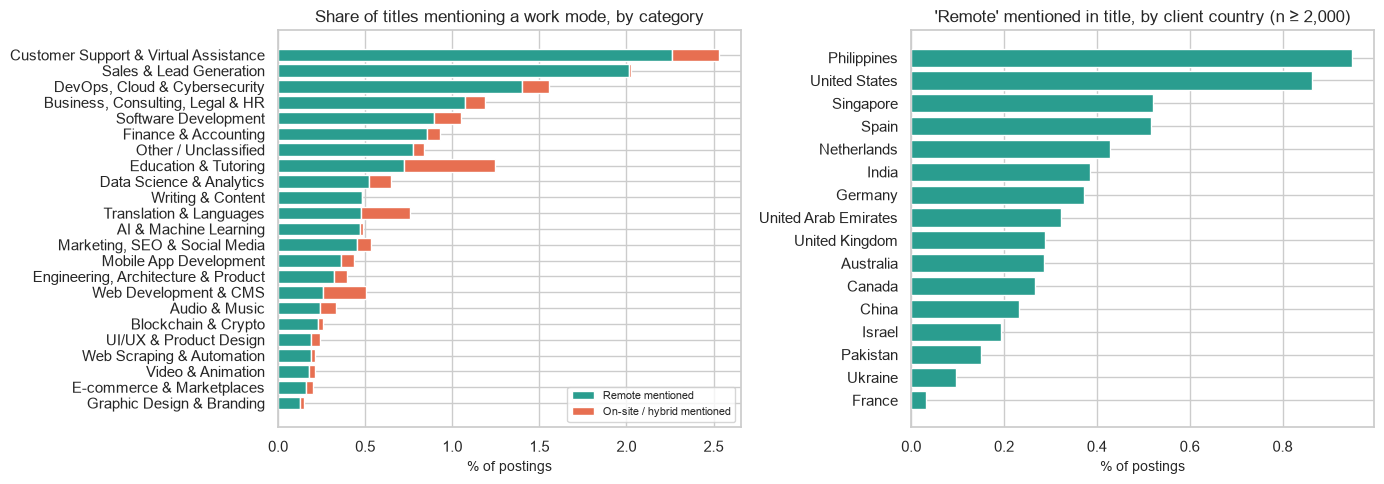

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bc = by_cat.sort_values("remote_%")
axes[0].barh(bc.index, bc["remote_%"], color="#2a9d8f", label="Remote mentioned")
axes[0].barh(bc.index, bc["onsite_or_hybrid_%"], left=bc["remote_%"], color="#e76f51", label="On-site / hybrid mentioned")
axes[0].set_title("Share of titles mentioning a work mode, by category"); axes[0].set_xlabel("% of postings"); axes[0].legend(fontsize=8)
bk = by_ctry.sort_values("remote_%")
axes[1].barh(bk.index, bk["remote_%"], color="#2a9d8f"); axes[1].set_title("'Remote' mentioned in title, by client country (n ≥ 2,000)")
axes[1].set_xlabel("% of postings")
plt.tight_layout(); plt.show()

### 9.1 Trend over time (core window, full weeks)

,n,remote_%,ci_low,ci_high,onsite_or_hybrid_%,hourly_share_%
week_start,,,,,,
2024-02-19,45449,0.57,0.50,0.64,0.10,58.52
2024-02-26,43546,0.54,0.48,0.61,0.12,56.99
2024-03-04,43615,0.54,0.48,0.62,0.09,57.80
2024-03-11,42915,0.53,0.47,0.60,0.07,56.53


'Remote mentioned' share across weeks: chi-square p = 0.877; Spearman(date, daily share) rho = -0.08 (p = 0.694)
Hourly-vs-fixed share across weeks:   chi-square p = 3.68e-09


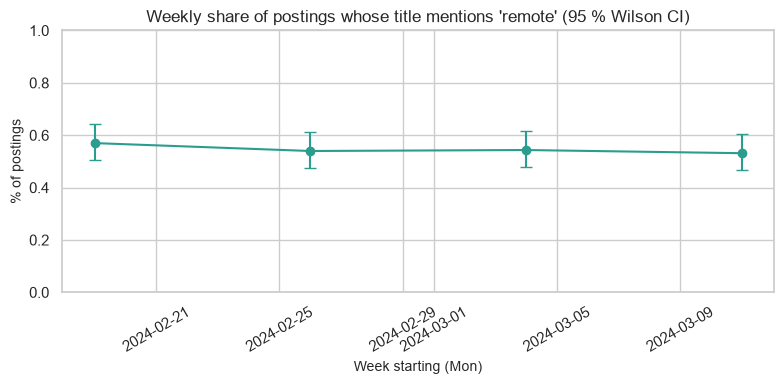

In [43]:
cw = core[core["week_start"].isin(full_weeks)]
wk = cw.groupby("week_start").agg(n=("link", "size"), remote=("work_mode_signal", lambda s: (s == "Remote mentioned").sum()),
                                  onsite_hybrid=("work_mode_signal", lambda s: s.isin(["On-site mentioned", "Hybrid mentioned"]).sum()),
                                  hourly=("pay_type", lambda s: (s == "Hourly").sum()))
wk["remote_%"] = 100 * wk["remote"] / wk["n"]
wk["ci_low"], wk["ci_high"] = zip(*[(100 * l, 100 * h) for l, h in (wilson(k, n) for k, n in zip(wk["remote"], wk["n"]))])
wk["onsite_or_hybrid_%"] = 100 * wk["onsite_hybrid"] / wk["n"]
wk["hourly_share_%"] = 100 * wk["hourly"] / wk["n"]
display(wk[["n", "remote_%", "ci_low", "ci_high", "onsite_or_hybrid_%", "hourly_share_%"]])

chi2, p_chi, *_ = stats.chi2_contingency(np.c_[wk["remote"], wk["n"] - wk["remote"]])
daily_share = cw.groupby("date").apply(lambda g: (g["work_mode_signal"] == "Remote mentioned").mean(), include_groups=False)
rho, p_rho = stats.spearmanr(np.arange(len(daily_share)), daily_share.values)
chi2h, p_h, *_ = stats.chi2_contingency(np.c_[wk["hourly"], wk["n"] - wk["hourly"]])
print(f"'Remote mentioned' share across weeks: chi-square p = {p_chi:.3f}; Spearman(date, daily share) rho = {rho:+.2f} (p = {p_rho:.3f})")
print(f"Hourly-vs-fixed share across weeks:   chi-square p = {p_h:.3g}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(wk.index, wk["remote_%"], yerr=[wk["remote_%"] - wk["ci_low"], wk["ci_high"] - wk["remote_%"]], marker="o", capsize=4, color="#2a9d8f")
ax.set_ylim(0, max(1.0, wk["ci_high"].max() * 1.2))
ax.set_title("Weekly share of postings whose title mentions 'remote' (95 % Wilson CI)"); ax.set_xlabel("Week starting (Mon)"); ax.set_ylabel("% of postings")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

### 9.2 Does mentioning "remote" go with different pay?

In [44]:
for col, label in (("hourly_mid_usd", "hourly rate"), ("fixed_budget_usd", "fixed budget")):
    d = jobs[jobs[col].notna()]
    a, b = d.loc[d["work_mode_signal"] == "Remote mentioned", col], d.loc[d["work_mode_signal"] == "No mention", col]
    u, p = stats.mannwhitneyu(a, b)
    print(f"{label}: median with 'remote' = {a.median():.1f} (n={len(a):,}) vs without = {b.median():.1f} (n={len(b):,}); "
          f"rank-biserial r = {2 * u / (len(a) * len(b)) - 1:+.2f}, p = {p:.1e}")

hourly rate: median with 'remote' = 25.0 (n=769) vs without = 22.5 (n=97,668); rank-biserial r = +0.07, p = 1.6e-03
fixed budget: median with 'remote' = 110.0 (n=338) vs without = 100.0 (n=103,282); rank-biserial r = +0.10, p = 8.9e-04


### 9.3 "Data-backed forecast" - what is defensible
If the weekly share is statistically stable (test above), the only honest forecast is **"about the same"**: we project the pooled share with its Wilson 95 % interval.
This says *nothing* about a long-run shift towards remote work, which this dataset cannot observe.

In [45]:
k, n = int(wk["remote"].sum()), int(wk["n"].sum())
lo, hi = wilson(k, n)
print(f"Pooled share of titles mentioning 'remote' over {len(wk)} full weeks: {100 * k / n:.2f}%  (95% CI {100 * lo:.2f}% – {100 * hi:.2f}%)")
print("Naive next-week projection: the same share, i.e. roughly "
      f"{int(round(wk['n'].mean() * k / n)):,} of ~{int(wk['n'].mean()):,} weekly postings. No trend can be claimed unless the tests above are significant.")

Pooled share of titles mentioning 'remote' over 4 full weeks: 0.55%  (95% CI 0.51% – 0.58%)
Naive next-week projection: the same share, i.e. roughly 240 of ~43,881 weekly postings. No trend can be claimed unless the tests above are significant.


### 9.4 conclusions
* **Everything here is remote work** (a freelance marketplace); explicit work-mode wording appears in well under 1 % of titles.
* On-site/hybrid mentions are very rare (many are local-service requests such as photo shoots or paralegal work); 'remote' mentions are more common but still well under 1 %.
* Over ~4 full weeks the 'remote mentioned' share shows no detectable change (chi-square and Spearman tests above). The hourly-vs-fixed split drifts by about two percentage points — statistically significant only because each week holds ~40,000 postings, and small in practical terms. **No conclusion about "the shift to remote work" is possible from this file.**
* Recommendation: repeat this analysis on a dataset with a real work-mode field and a multi-year span.

## 10. Saving analysis tables (inputs for notebooks 2-3 and for reporting)

In [46]:
TABLE_DIR = OUTPUT_DIR / "tables"; TABLE_DIR.mkdir(exist_ok=True)
kw_h.assign(pay_measure="hourly").pipe(lambda d: pd.concat([d, kw_f.assign(pay_measure="fixed")])).to_csv(TABLE_DIR / "task1_keyword_salary_effects.csv", index=False)
growth.to_csv(TABLE_DIR / "task2_category_growth.csv", index=False)
sig.to_csv(TABLE_DIR / "task2_keyword_growth.csv", index=False)
country_rates.to_csv(TABLE_DIR / "task4_hourly_rate_by_country.csv", index=False)
wk.to_csv(TABLE_DIR / "task7_weekly_work_mode_signal.csv")
print("Saved:", sorted(p.name for p in TABLE_DIR.iterdir()))

Saved: ['task1_keyword_salary_effects.csv', 'task2_category_growth.csv', 'task2_keyword_growth.csv', 'task4_hourly_rate_by_country.csv', 'task7_weekly_work_mode_signal.csv']


## 11. Limitations and caveats
* **Short, single-platform window:** ~5 weeks of reliable data from one marketplace → no seasonality, no year-over-year growth, results may not generalise to the wider job market.
* **Collection gaps** (14–15 Feb, parts of 17–18 Feb, partial first/last day) → trend work uses only complete days.
* **Derived categories**, not official ones; rule-based keyword matching misclassifies some titles (≈ 11 % unclassified).
* **No** description, skills, company, experience level or work mode in the data; weak title proxies are labelled as such.
* **Pay** is advertised (not realised), assumed USD, partly undisclosed (30 % of hourly postings), and affected by round-number anchoring and a few placeholder extremes.
* **Client country ≠ job location.** Repost duplicates cannot be separated from genuinely new demand (no client id).
* All findings are **associations**, not causal effects.